# Evaluating feed-forward cameras against COLMAP and ground truth

**What this notebook does.** It measures how good the cameras predicted by feed-forward models
are: VGGT-1B and Depth Anything 3 (DA3-Base and DA3-Large-1.1, each with its *camera head* and
its *ray head*). It also evaluates COLMAP on the same images. Three scenes with three kinds of
reference are used:

| scene | images | reference |
|---|---|---|
| Kitchen (VGGT example) | 25 | COLMAP SfM computed here (pseudo ground truth) |
| South Building (COLMAP dataset) | 24 of 128 | COLMAP model shipped with the dataset (all 128 full-resolution photos) |
| TUM RGB-D fr1_desk | 24 keyframes | motion-capture ground truth (metres) |

**What you'll learn**
- why reconstructions can only be compared up to a similarity transform (gauge freedom), and
  how the Umeyama Sim(3) alignment removes it;
- the gauge-free pairwise metrics used in the VGGT / DA3 papers: relative rotation error,
  relative translation-*direction* error, and AUC@5/10/15/30 degrees;
- absolute metrics after alignment (rotation error, ATE) and their pitfalls;
- how the Depth Anything 3 API works, and camera head vs ray head;
- how feed-forward models compare to COLMAP in accuracy, runtime and memory.

**Prerequisites:** notebook 01 of this project; Umeyama / ATE from project 12 helps.
The heavy model runs come from `benchmark.py` (cached in `runs/10_feedforward_3d/preds/`);
this notebook re-runs only DA3-Base live, to show the API.

## Setup

In [1]:
# --- Setup: imports, device, repository paths, plotting style ---
# The project helpers live in projects/10_feedforward_3d/scripts/ff3d.py (shared with the
# benchmark script and the solutions), so every number below comes from the same code.
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cvlab import viz
from cvlab.device import setup
from cvlab.io import project_dir

PROJECT = "10_feedforward_3d"
sys.path.insert(0, str(project_dir(PROJECT) / "scripts"))
import ff3d  # noqa: E402

device = setup(seed=0)
viz.set_style()
pd.set_option("display.precision", 3)
print("results dir:", ff3d.rel(ff3d.results_path()))

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)
results dir: projects/10_feedforward_3d/results


## 1. Three scenes, three references
A reference is only as good as its own errors. COLMAP on 25 images is a **pseudo ground truth**:
excellent rotations, but it can drop images. The South Building reference is much stronger,
since it was reconstructed from all 128 photos at 3072x2304 px. The TUM motion-capture system
measures the real camera trajectory in metres, with millimetre-level accuracy (plus small
time-synchronisation errors).

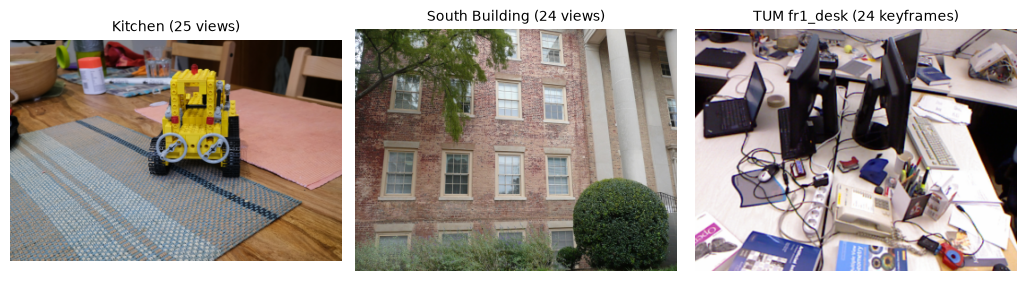

,scene,images,reference,reference poses,COLMAP registered (this project),"COLMAP time (s, CPU)"
0,Kitchen (25 views),25,colmap,24,24/25,9.15
1,South Building (24 views),24,dataset_colmap,24,22/24,13.41
2,TUM fr1_desk (24 keyframes),24,mocap,24,24/24,6.62


In [2]:
# --- Load the scenes and the COLMAP run statistics (run_colmap.py) ---
from cvlab.io import read_image

scene_names = ["kitchen", "south_building", "tum_desk"]
scenes = {n: ff3d.load_scene(n) for n in scene_names}
colmap_stats = pd.read_csv(ff3d.results_path("colmap_summary.csv")).set_index("scene")
info = pd.DataFrame([{
    "scene": s.label, "images": len(s), "reference": s.ref_kind,
    "reference poses": int(s.has_ref.sum()),
    "COLMAP registered (this project)": f"{colmap_stats.loc[n, 'n_registered']}/{len(s)}",
    "COLMAP time (s, CPU)": colmap_stats.loc[n, "total_s"],
} for n, s in scenes.items()])
fig = viz.show_images([read_image(s.image_paths[len(s) // 2], max_side=360) for s in scenes.values()],
                      titles=[s.label for s in scenes.values()], ncols=3, size=3.4)
plt.show()
info

## 2. The COLMAP reference for the kitchen
`run_colmap.py` ran SIFT extraction, exhaustive matching and incremental SfM with pycolmap on
the CPU. The output is a sparse point cloud (triangulated SIFT tracks) plus one bundle-adjusted
`SIMPLE_RADIAL` camera shared by all images. Image `01.png` could not be registered.

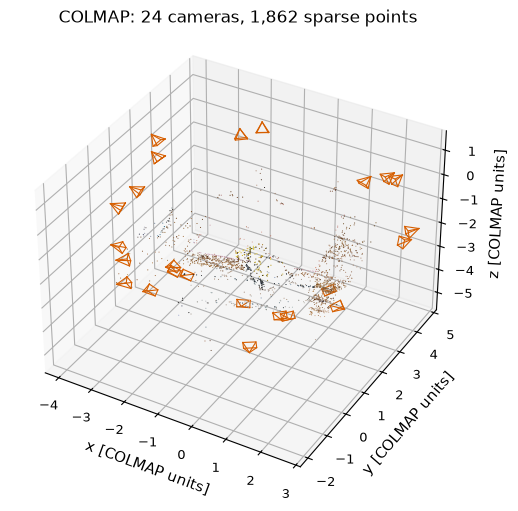

mean reprojection error 0.325 px, mean track length 3.95 views


In [3]:
# --- Load the kitchen COLMAP model and plot its sparse points and cameras ---
kitchen = scenes["kitchen"]
rec_colmap = ff3d.load_colmap(ff3d.runs_path("colmap", "kitchen"))
xyz, rgb = ff3d.colmap_points(rec_colmap)
ok = kitchen.has_ref
R_up = ff3d.upright_rotation(kitchen.ref_T_cw[ok])
ext = ff3d.trajectory_extent(ff3d.camera_centers(kitchen.ref_T_cw[ok]))
fig = plt.figure(figsize=(6.5, 5))
ax = fig.add_subplot(projection="3d")
pts, cols = ff3d.crop_to_core(xyz @ R_up.T, rgb / 255.0, 0.95)
ff3d.plot_scene(ax, pts, cols, ff3d.sim3_apply_poses(kitchen.ref_T_cw[ok], 1.0, R_up, np.zeros(3)),
                kitchen.ref_K[ok][0], (kitchen.ref_size[1], kitchen.ref_size[0]),
                frustum_scale=0.04 * ext, elev=35, azim=-60, units="COLMAP units",
                title=f"COLMAP: {rec_colmap.num_reg_images()} cameras, {len(xyz):,} sparse points")
plt.show()
print(f"mean reprojection error {rec_colmap.compute_mean_reprojection_error():.3f} px, "
      f"mean track length {rec_colmap.compute_mean_track_length():.2f} views")

## 3. Gauge freedom and the Umeyama Sim(3) alignment
From images alone, a reconstruction is only defined up to a similarity transform
$X \mapsto sRX + \mathbf t$ (7 degrees of freedom): the world origin, its orientation and the
global scale are arbitrary. VGGT puts the origin at camera 0 and normalises the scale; COLMAP
picks the frame of its initial image pair. Before comparing **absolute** positions we fit the
Sim(3) that best maps the predicted camera centres $\mathbf p_i$ onto the reference centres
$\mathbf r_i$:

$$\min_{s,R,\mathbf t} \sum_i \lVert \mathbf r_i - (sR\,\mathbf p_i + \mathbf t)\rVert^2 .$$

Umeyama (1991) gives the closed form. Centre both sets ($\boldsymbol\mu_p$, $\boldsymbol\mu_r$),
take the SVD of the cross-covariance $\Sigma = \tfrac1n\sum_i(\mathbf r_i-\boldsymbol\mu_r)(\mathbf p_i-\boldsymbol\mu_p)^\top = UDV^\top$, then

$$R = U S V^\top,\quad S=\mathrm{diag}(1,1,\det U\det V),\quad s = \frac{\mathrm{tr}(DS)}{\sigma_p^2},\quad \mathbf t = \boldsymbol\mu_r - sR\boldsymbol\mu_p .$$

After alignment, the rotation error of camera $i$ is the geodesic angle
$\arccos\!\big(\tfrac{\mathrm{tr}(R_{\text{ref},i}^\top R\,R_{\text{pred},i}) - 1}{2}\big)$ (camera-to-world rotations), and the
**ATE** is the RMS distance between aligned and reference centres. We report it as a % of the
reference trajectory diameter, because COLMAP units are arbitrary.

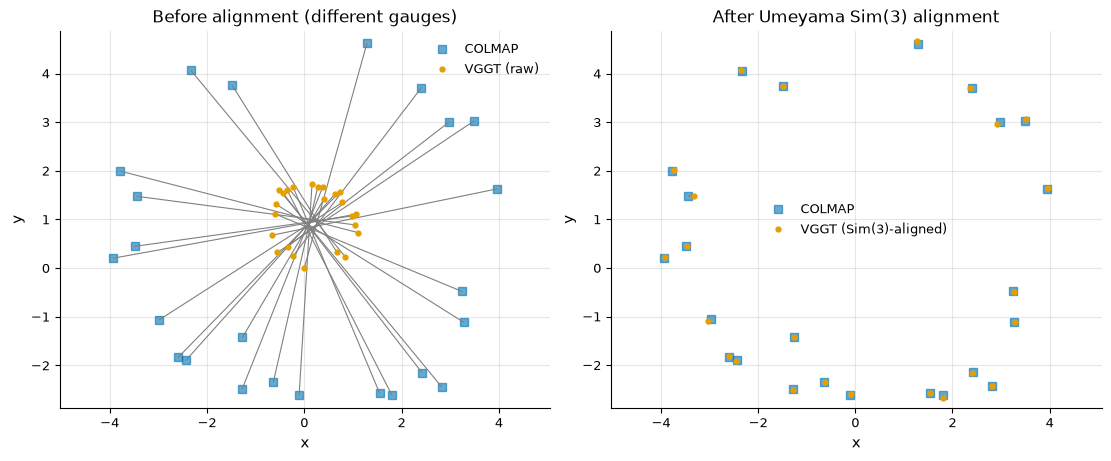

scale s = 4.312 | median rotation error 0.51 deg | ATE 0.59 % of the trajectory diameter


In [4]:
# --- Align the cached VGGT cameras of the kitchen to COLMAP ---
# predict_cached() loads runs/10_feedforward_3d/preds/kitchen/vggt.npz written by benchmark.py
# (and would run the model if the cache were missing).
vggt_k = ff3d.predict_cached(kitchen, "vggt")
al = ff3d.sim3_align(vggt_k.T_cw[ok], kitchen.ref_T_cw[ok])
C_ref = ff3d.camera_centers(kitchen.ref_T_cw[ok]) @ R_up.T
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
# connect=False: the kitchen photos are unordered, so grey segments link each camera pair.
ff3d.plot_cameras_topdown(axes[0], {"COLMAP": C_ref, "VGGT (raw)": ff3d.camera_centers(vggt_k.T_cw[ok]) @ R_up.T},
                          dims=(0, 1), title="Before alignment (different gauges)", connect=False)
ff3d.plot_cameras_topdown(axes[1], {"COLMAP": C_ref, "VGGT (Sim(3)-aligned)": al["T_wc_aligned"][:, :3, 3] @ R_up.T},
                          dims=(0, 1), title="After Umeyama Sim(3) alignment", connect=False)
plt.show()
print(f"scale s = {al['s']:.3f} | median rotation error {np.median(al['rot_err_deg']):.2f} deg | "
      f"ATE {100 * np.sqrt(np.mean(al['centre_err'] ** 2)) / ext:.2f} % of the trajectory diameter")

## 4. Gauge-free pairwise metrics and AUC
Absolute errors depend on the alignment: one bad camera pulls the Sim(3) fit and spreads its
error to every other camera. The VGGT and DA3 papers therefore score **every pair** $(i, j)$
by its *relative* pose $T_{ji} = T_j T_i^{-1}$, which does not depend on the gauge:

$$e_R(i,j) = \angle\big(R^{\text{ref}\top}_{ji} R^{\text{pred}}_{ji}\big), \qquad
e_t(i,j) = \angle\big(\mathbf t^{\text{pred}}_{ji},\ \mathbf t^{\text{ref}}_{ji}\big).$$

Only the **direction** of the relative translation is compared, because each reconstruction
has its own scale. A pair is as good as its worse error, $e = \max(e_R, e_t)$. The accuracy
curve $\text{acc}(\tau) = \Pr[e < \tau]$ is then integrated over $\tau \in [0, \tau_{\max}]$
on 1-degree bins (the official `calculate_auc_np`):

$$\text{AUC}@\tau_{\max} = \frac{1}{\tau_{\max}}\sum_{k=1}^{\tau_{\max}} \text{acc}(k).$$

AUC@30 = 1 would mean every pair is within 1 degree. A method with all pairs within
3 degrees still scores well below 1 on AUC@5, so AUC@5 is the most demanding of the four.

In [5]:
# --- Pairwise errors of VGGT on the kitchen and the resulting AUCs ---
pe = ff3d.relative_pose_errors(vggt_k.T_cw[ok], kitchen.ref_T_cw[ok])
err = np.maximum(pe["rot_deg"], pe["trans_deg"])
print(f"{len(err)} pairs | median rotation error {np.median(pe['rot_deg']):.2f} deg | "
      f"median translation-direction error {np.median(pe['trans_deg']):.2f} deg")
for k in ff3d.AUC_THRESHOLDS:
    print(f"AUC@{k:<2d} = {ff3d.pose_auc(pe['rot_deg'], pe['trans_deg'], k):.3f}")
worst = pe["pairs"][np.argmax(err)]
names_ok = [n for n, o in zip(kitchen.names, ok) if o]
print(f"worst pair: {names_ok[worst[0]]} - {names_ok[worst[1]]} (e = {err.max():.1f} deg)")

276 pairs | median rotation error 0.54 deg | median translation-direction error 0.50 deg
AUC@5  = 0.941
AUC@10 = 0.971
AUC@15 = 0.980
AUC@30 = 0.990
worst pair: 05.png - 07.png (e = 3.6 deg)


## 5. Depth Anything 3 live: camera head vs ray head
DA3 uses a single plain DINOv2 transformer with cross-view attention and predicts a **depth
map** plus a **ray map** per pixel (ray origin + direction), from which a camera can be
recovered. It also has a small **camera head** that regresses the pose directly.
`DepthAnything3.inference` takes a list of images and returns `extrinsics` (N x 3 x 4,
OpenCV camera-from-world), `intrinsics`, `depth` and `conf`. With `use_ray_pose=True` the
cameras are fitted to the ray maps instead of being read from the camera head. The
`ref_view_strategy` picks which view becomes the reference frame, and the output order is
restored afterwards. DA3-Base (Apache-2.0, the smallest pose-capable size we test) runs live
here. The ray-head pose is fitted to the predicted rays with a randomised solver, so its
metrics can differ from the cached benchmark run in the third decimal; the camera head is
deterministic.

In [6]:
# --- Run DA3-Base on the kitchen with both pose heads and evaluate ---
da3 = ff3d.DA3Runner("da3-base")
_ = da3.predict(kitchen.image_paths[:2])  # warm-up
live = {}
for method, ray in [("da3-base", False), ("da3-base-ray", True)]:
    r = da3.predict(kitchen.image_paths, use_ray_pose=ray, method=method)
    m = ff3d.evaluate_poses(r.T_cw, kitchen.ref_T_cw)
    live[method] = {"AUC@5": m["auc@5"], "AUC@15": m["auc@15"], "forward (s)": r.runtime_s,
                    "total (s)": r.total_s, "peak VRAM (MiB)": r.peak_vram_mb}
print(f"DA3-Base: {da3.n_params / 1e6:.0f} M parameters, weights {da3.weights_vram_mb:.0f} MiB, "
      f"network input {r.proc_hw[1]}x{r.proc_hw[0]} px")
del da3
pd.DataFrame(live).T

DA3-Base: 135 M parameters, weights 516 MiB, network input 504x336 px


,AUC@5,AUC@15,forward (s),total (s),peak VRAM (MiB)
da3-base,0.622,0.874,1.237,1.526,2753.875
da3-base-ray,0.683,0.894,1.841,2.145,3135.352


## 6. Every method on every scene
`benchmark.py` ran VGGT-1B and DA3-Base/Large (both heads) on the three scenes and cached
their predictions. Here we recompute all metrics from those caches, so the code path is
visible, and check that they match `results/pose_metrics.csv`. COLMAP (subset) is evaluated
on South Building and TUM; on the kitchen it *is* the reference.

In [7]:
# --- Recompute the pose metrics of all cached predictions ---
methods = ["vggt", "da3-base", "da3-base-ray", "da3-large", "da3-large-ray", "colmap"]
rows, recs = [], {}
for n, s in scenes.items():
    for meth in methods:
        if meth == "colmap" and s.ref_kind == "colmap":
            continue  # COLMAP is the kitchen reference itself
        r = ff3d.predict_cached(s, meth)
        recs[(n, meth)] = r
        m = ff3d.evaluate_poses(r.T_cw, s.ref_T_cw, metric_units=s.ref_kind == "mocap")
        rows.append({"scene": n, "method": meth, **m, "runtime_s": r.runtime_s,
                     "peak_vram_mb": r.peak_vram_mb})
metrics = pd.DataFrame(rows)
saved = pd.read_csv(ff3d.results_path("pose_metrics.csv"))
check = metrics.merge(saved, on=["scene", "method"], suffixes=("", "_saved"))
print("max |AUC@15 - saved| =", float(np.abs(check["auc@15"] - check["auc@15_saved"]).max()))

max |AUC@15 - saved| = 4.782608695519386e-06


## Results
### Pose accuracy per scene
AUC@5 is the strict metric (sub-degree agreement); AUC@30 forgives small errors and mostly
flags gross failures. Short labels: DA3-B = DA3-Base, DA3-L = DA3-Large-1.1; "cam" and "ray"
name the pose head.

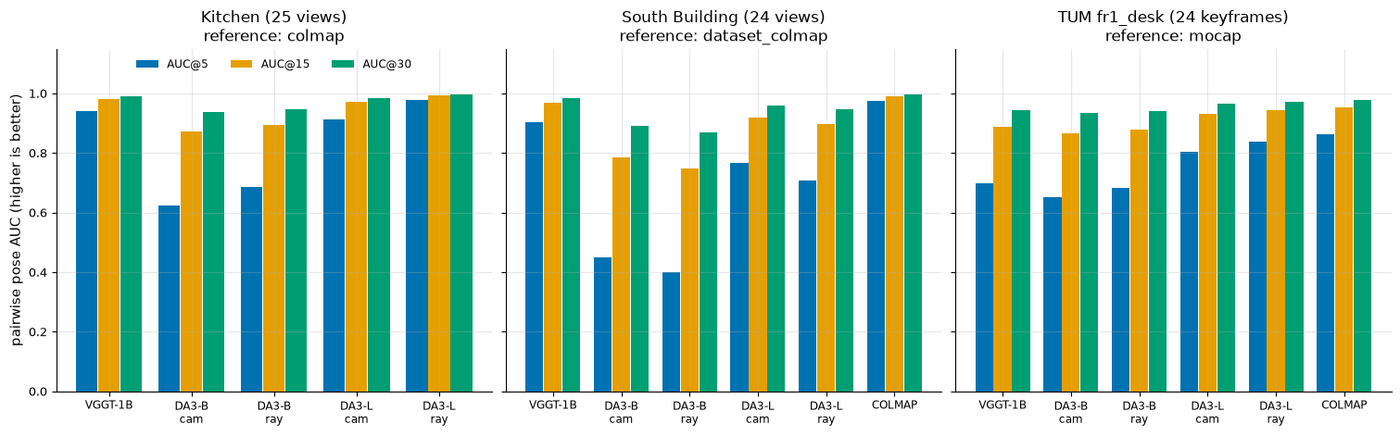

In [8]:
# --- Grouped bars: AUC@5 / AUC@15 / AUC@30 per method, one panel per scene ---
labels = {m: ff3d.METHOD_LABELS[m] for m in methods}
short = {"vggt": "VGGT-1B", "da3-base": "DA3-B\ncam", "da3-base-ray": "DA3-B\nray",
         "da3-large": "DA3-L\ncam", "da3-large-ray": "DA3-L\nray", "colmap": "COLMAP"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for ax, n in zip(axes, scene_names):
    d = metrics[metrics.scene == n].set_index("method")
    x = np.arange(len(d))
    for k, (col, w) in enumerate([("auc@5", -0.27), ("auc@15", 0.0), ("auc@30", 0.27)]):
        ax.bar(x + w, d[col], width=0.26, label=col.upper(), color=viz.color(k, unit=True))
    ax.set_xticks(x, [short[m] for m in d.index], rotation=0, fontsize=8.5)
    ax.set_title(f"{scenes[n].label}\nreference: {scenes[n].ref_kind}")
    ax.set_ylim(0, 1.15)
    ax.set_yticks(np.linspace(0, 1, 6))
axes[0].set_ylabel("pairwise pose AUC (higher is better)")
axes[0].legend(loc="upper center", ncol=3, fontsize=8.5)
viz.savefig(fig, PROJECT, "pose_auc_bars")
plt.show()

### Error distributions
The cumulative distribution of the per-pair error $\max(e_R, e_t)$ shows *where* methods
differ: in the bulk of the pairs (curve height at a few degrees) or in a tail of failures
(where the curve flattens out).

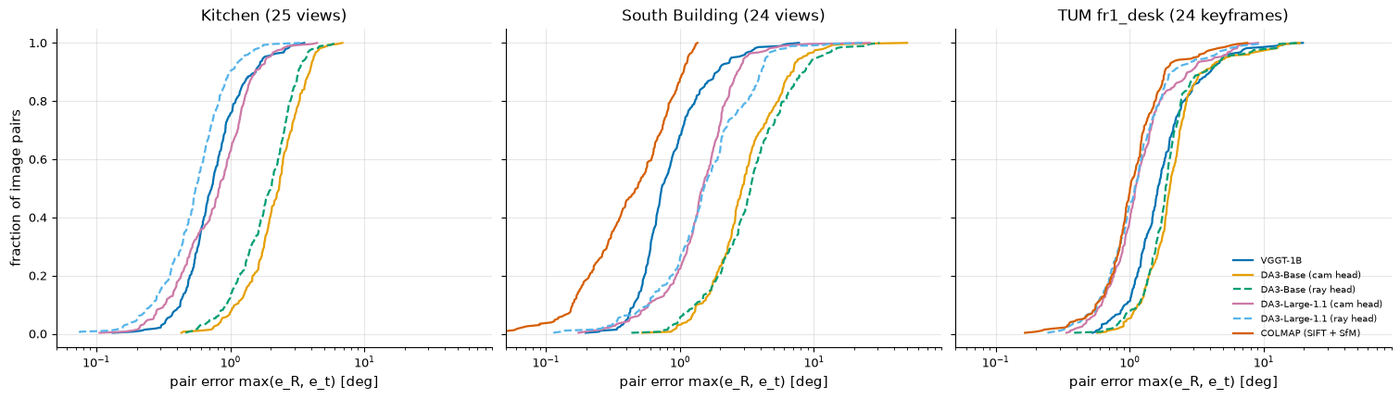

In [9]:
# --- CDF of the pairwise pose error per method and scene ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, n in zip(axes, scene_names):
    s = scenes[n]
    for k, meth in enumerate(methods):
        if (n, meth) not in recs:
            continue
        r = recs[(n, meth)]
        both = np.isfinite(r.T_cw).all(axis=(1, 2)) & s.has_ref
        pe_m = ff3d.relative_pose_errors(r.T_cw[both], s.ref_T_cw[both])
        e = np.sort(np.maximum(pe_m["rot_deg"], pe_m["trans_deg"]))
        ax.plot(e, np.arange(1, len(e) + 1) / len(e), label=labels[meth], color=viz.color(k, unit=True),
                lw=1.6, ls="--" if "ray" in meth else "-")
    ax.set_xscale("log")
    ax.set_xlim(0.05, 90)
    ax.set_xlabel("pair error max(e_R, e_t) [deg]")
    ax.set_title(s.label)
axes[0].set_ylabel("fraction of image pairs")
axes[2].legend(loc="lower right", fontsize=7.5)
viz.savefig(fig, PROJECT, "pose_error_cdf")
plt.show()

### Trajectories after Sim(3) alignment
On TUM the reference is metric, so the aligned trajectories are in metres. The Sim(3) scale
also gives the **metric scale of the reconstruction**, which notebook 03 uses to evaluate depth.

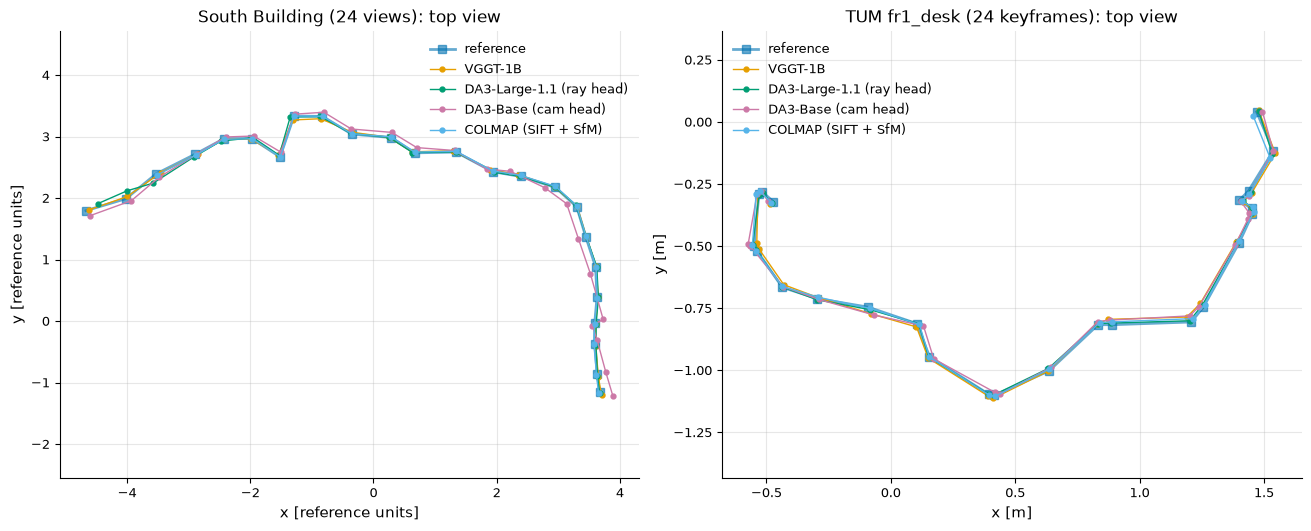

In [10]:
# --- Top-down camera centres: reference vs methods (aligned), South Building and TUM ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, n, units in [(axes[0], "south_building", "reference units"), (axes[1], "tum_desk", "m")]:
    s = scenes[n]
    R_u = ff3d.upright_rotation(s.ref_T_cw)
    cents = {"reference": ff3d.camera_centers(s.ref_T_cw) @ R_u.T}
    for meth in ["vggt", "da3-large-ray", "da3-base", "colmap"]:
        r = recs[(n, meth)]
        both = np.isfinite(r.T_cw).all(axis=(1, 2))
        a = ff3d.sim3_align(r.T_cw[both], s.ref_T_cw[both])
        cents[labels[meth]] = a["T_wc_aligned"][:, :3, 3] @ R_u.T
    ff3d.plot_cameras_topdown(ax, cents, dims=(0, 1), units=units, title=f"{s.label}: top view")
viz.savefig(fig, PROJECT, "trajectories_aligned")
plt.show()

### Summary table
`runtime` is the network forward pass for the feed-forward models (GPU, after a warm-up) and
the full SIFT + matching + SfM wall-clock for COLMAP (CPU, 24 threads). Peak VRAM includes the
weights. ATE is in % of the reference trajectory diameter (and in cm for TUM).

In [11]:
# --- Summary of all measured pose metrics ---
table = metrics.assign(
    method=metrics.method.map(labels), images=metrics.n_eval.astype(str) + "/" + metrics.n_total.astype(str),
    ate_cm=100 * metrics.get("ate_m"),
)[["scene", "method", "images", "auc@5", "auc@15", "auc@30", "rra@5", "rta@5", "abs_rot_med_deg",
   "ate_pct", "ate_cm", "runtime_s", "peak_vram_mb"]]
table.columns = ["scene", "method", "evaluated", "AUC@5", "AUC@15", "AUC@30", "RRA@5", "RTA@5",
                 "rot. err med (deg)", "ATE (% diam.)", "ATE (cm)", "runtime (s)", "peak VRAM (MiB)"]
table.round(3)

,scene,method,evaluated,AUC@5,AUC@15,AUC@30,RRA@5,RTA@5,rot. err med (deg),ATE (% diam.),ATE (cm),runtime (s),peak VRAM (MiB)
0,kitchen,VGGT-1B,24/25,0.941,0.980,0.990,1.000,1.000,0.507,0.588,NaN,6.610,5275.731
1,kitchen,DA3-Base (cam head),24/25,0.622,0.874,0.937,1.000,0.982,1.284,1.234,NaN,1.134,2753.875
2,kitchen,DA3-Base (ray head),24/25,0.687,0.895,0.948,1.000,0.989,1.234,1.027,NaN,1.693,3135.367
3,kitchen,DA3-Large-1.1 (cam head),24/25,0.912,0.971,0.985,1.000,1.000,0.470,0.357,NaN,3.125,5822.978
4,kitchen,DA3-Large-1.1 (ray head),24/25,0.978,0.993,0.996,1.000,1.000,0.283,0.287,NaN,3.728,5822.993
5,south_building,VGGT-1B,24/24,0.904,0.967,0.984,1.000,0.986,0.478,0.506,NaN,7.306,5533.554
6,south_building,DA3-Base (cam head),24/24,0.449,0.786,0.891,0.866,0.859,1.575,1.550,NaN,1.223,2984.671
7,south_building,DA3-Base (ray head),24/24,0.401,0.748,0.869,0.797,0.855,3.978,1.677,NaN,1.862,3279.586
8,south_building,DA3-Large-1.1 (cam head),24/24,0.767,0.919,0.958,1.000,0.982,1.603,0.849,NaN,3.445,6226.093
9,south_building,DA3-Large-1.1 (ray head),24/24,0.709,0.897,0.947,1.000,0.971,1.110,0.918,NaN,4.066,6226.093


**Takeaways**

- **There is no universal winner, and the reference matters.** On the kitchen (scored against
  a COLMAP pseudo ground truth) DA3-Large-1.1 with its ray head is best (AUC@5 0.978, VGGT
  0.941). On South Building (reference from all 128 full-resolution photos) VGGT is the best
  feed-forward model (AUC@5 0.904 vs 0.767 for DA3-Large). On TUM (motion capture) DA3-Large
  with the ray head leads again (0.839 vs 0.698 for VGGT).
- **COLMAP is still the most accurate where it succeeds**: AUC@5 0.975 on South Building and
  0.862 on TUM. But it dropped images (1 of 25 on the kitchen, 2 of 24 on South Building) and
  took 6.6-13.4 s of 24-thread CPU time. The feed-forward models always return a pose for every
  image, which matters for a robot that cannot re-take a photo.
- **Model size matters more than the pose head.** DA3-Base (135 M parameters) trails
  DA3-Large by 0.15-0.32 AUC@5 on every scene. The ray head gains 0.03-0.07 AUC@5 over the
  camera head on the kitchen and TUM but loses 0.05-0.06 on South Building, so "the ray head is
  more accurate" is not a rule.
- **Strict vs lenient thresholds**: AUC@30 is at least 0.87 for every method, so nothing fails
  grossly on these short, overlapping sequences; the differences live in the 0.5-5 degree range
  that AUC@5 resolves.
- **In metres** (TUM, Sim(3)-aligned, trajectory diameter 2.1 m), the camera-centre ATE is
  1.0-1.1 cm for DA3-Large, 1.3 cm for COLMAP, 1.5 cm for VGGT and 2.1-2.2 cm for DA3-Base.
- **Cost on the RTX 5060 Laptop GPU (8 GB)**: DA3-Base runs 24-25 views in 1.1-1.9 s with
  at most 3280 MiB peak VRAM; DA3-Large takes 3.1-4.1 s and 5823-6226 MiB; VGGT-1B takes
  6.6-7.3 s and 5276-5534 MiB (with the bf16 backbone of notebook 01).

## Exercises
Solutions: `projects/10_feedforward_3d/solutions/solutions_02.py`.

**Exercise 1 - accuracy at a threshold.** Besides AUC, papers report RRA@$\tau$ and RTA@$\tau$:
the fraction of pairs whose relative rotation (translation-direction) error is below $\tau$.
Plot both against $\tau \in [0.5, 30]$ degrees for VGGT and DA3-Large (ray head) on South Building.

In [12]:
# --- Exercise 1: RRA / RTA curves ---
# TODO: use ff3d.relative_pose_errors on recs[("south_building", m)] and plot the fraction of
#       pairs below each threshold.

**Exercise 2 - the sign ambiguity of the translation direction.** The official Co3D evaluation
of VGGT folds the translation error as $\min(e_t, 180^\circ - e_t)$, so a translation pointing
backwards is not penalised. Recompute AUC@15 with this convention for every method on TUM. Which
methods gain, and why could a backwards translation happen at all?

In [13]:
# --- Exercise 2: translation-direction ambiguity ---
# TODO: fold pe["trans_deg"] and recompute ff3d.pose_auc for each method.

**Exercise 3 - SE(3) vs Sim(3).** Align VGGT's TUM trajectory to the ground truth with
`cvlab.geometry.umeyama_alignment(..., with_scale=False)` and compute the ATE in metres. Compare
with the Sim(3) ATE and explain the difference.

In [14]:
# --- Exercise 3: alignment without scale ---
# TODO: rigid (SE(3)) Umeyama on the camera centres, then RMSE of the residuals.